# explore — single-day stock selection workbench

Parameters are set at the top; then run in order: **data → factors → standardization → scoring → clustering → automatic selection → manual list → MVO → single-period evaluation → comparison with the backtest**.
Computes only one `as_of`, does not loop over historical dates, and does not save a run record.

| Section | Usage |
| --- | --- |
| A, B | View the fixed data source and task setup |
| This date | Fill in a trading day that has data; does not use the final `decision_date` |
| D, E | Same parameters and initial values as `run.ipynb`, edited in one place |
| Results | One cell per step; the score table or final list can be overridden |

On first use, Run All to see the automatic results. After changing upstream parameters, rerun downward from the corresponding parameter cell; after changing a manual override cell, rerun downward from that cell.
Displays keep all stocks, NaN means unavailable; formatting only affects display.

In [61]:
%load_ext autoreload
%autoreload 2

from dataclasses import asdict

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.cluster.hierarchy import dendrogram

import pf.backtest
import pf.cluster
import pf.config
import pf.factors
import pf.loader
import pf.metrics
import pf.scoring
import pf.selection
import pf.weights

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## A, B locked parameters (view only, do not change)

A data source (`DataSpec`) and B task constraints (`TaskSpec`) are shared by all runs, keeping results comparable and the portfolio compliant.

In [62]:
cfg = pf.config.Config()

display(pd.Series(asdict(cfg.data), name="A Data source").to_frame())
display(pd.Series({k: v for k, v in asdict(cfg.task).items() if k != "eval"}, name="B Task constraints").to_frame())
display(pd.Series(asdict(cfg.task.eval), name="B Evaluation setup (EvalSpec)").to_frame())

,A Data source
price_file,prices_raw.csv
price_col,close
revenue_file,revenue_adjusted.csv
benchmark_file,benchmark.csv
benchmark,^GSPC


,B Task constraints
decision_date,2026-10-12
holding_days,39
periods_per_year,252


,B Evaluation setup (EvalSpec)
risk_free,^IRX
index_baselines,"(^GSPC,)"
reference_tickers,"(NVDA,)"
mom_k,3
mom_lookback,252
mom_skip,21
n_random,1000
random_seed,2026
quantiles,"(0.1, 0.9)"


## This date

The default date leaves a full subsequent holding period for evaluation. You can also use the latest trading day: the portfolio is generated as usual, and holding returns and evaluation are skipped when fewer than H days follow.

In [63]:
as_of = pd.Timestamp("2026-10-12")
display(pd.Series({"as_of": as_of.date(), "holding_days": cfg.task.holding_days}, name="This exploration").to_frame())

,This exploration
as_of,2026-10-12
holding_days,39


## D Factor weights (defaults are fine)

Which factors are enabled is determined by the keys in the weights. To turn off a factor, delete it; do not set its weight to 0
(`0 × NaN = NaN`, so a factor with missing values would still make the total score NaN).

In [64]:
# Total score S = Σ σ_k · z_k. To turn off a factor use del cfg.factor_weights["<factor name>"]; do not set it to 0
cfg.factor_weights["momentum"] = 0.4        # σ1
cfg.factor_weights["downside_vol"] = 0.3    # σ2
cfg.factor_weights["revenue_growth"] = 0.4  # σ3
cfg.factor_weights["ret"] = 0.3             # σ4

display(pd.Series(cfg.factor_weights, name="D Factor weights").to_frame())

,D Factor weights
momentum,0.4
downside_vol,0.3
revenue_growth,0.4
ret,0.3


## E Detailed parameters (defaults are fine)

Four cells in pipeline order: factors → standardization → selection → weights.

### E1 Factor parameters

In [65]:
# momentum: P[t−skip] / P[t−lookback] − 1, in trading days; lookback > skip ≥ 0
cfg.factors.momentum.lookback = 189
cfg.factors.momentum.skip = 21

# downside_vol: −√(A · mean(min(r − tau, 0)²)), over the window daily returns up to as_of; A is the B-class periods_per_year
cfg.factors.downside_vol.window = 252
cfg.factors.downside_vol.tau = 0.0

# revenue_growth: (Rev[q] − Rev[q−k]) / Rev[q−k], q is the latest effective fiscal quarter (effective the day after announcement); method ∈ {"yoy", "qoq"}
cfg.factors.revenue_growth.method = "yoy"

# ret uses the config.KNNParams defaults; see knn_test.ipynb for standalone tuning.

factor_view = asdict(cfg.factors)
factor_view.pop("ret")
display(pd.Series(pd.json_normalize(factor_view).to_dict("records")[0], name="E1 Factor params (excl. frozen KNN)", dtype=object).to_frame())
print("ret/KNN: uses the frozen defaults in config.KNNParams; for tuning see notebooks/knn_test.ipynb")


,E1 Factor params (excl. frozen KNN)
momentum.lookback,189
momentum.skip,21
downside_vol.window,252
downside_vol.tau,0.0
revenue_growth.method,yoy


ret/KNN: uses the frozen defaults in config.KNNParams; for tuning see notebooks/knn_test.ipynb


### E2 Standardization

In [66]:
# Shared by all factors: clip at median ± n·MAD (MAD not multiplied by 1.4826), then take a cross-sectional z-score; n > 0
cfg.standardize.n = 5.0

display(pd.Series(asdict(cfg.standardize), name="E2 Standardize").to_frame())

,E2 Standardize
n,5.0


### E3 Stock selection

In [67]:
# Clustering (pf.cluster.hierarchical): adds a cluster column to the score table (A is the largest cluster); selection uses it to cap stocks per cluster
#   distance d = √(2(1 − ρ)), ρ is the correlation of the window daily returns up to as_of (with remove_market, the OLS residuals on mkt)
cfg.cluster.window = 250            # number of daily returns, ≥ 3; 120–250 recommended, below 120 the correlation estimate is too noisy
cfg.cluster.remove_market = True    # True: OLS with intercept on mkt, cluster on residuals (removing common market moves)
cfg.cluster.mkt = "^GSPC"           # market proxy, ∈ {"^GSPC", "^IXIC", "^NDX", "^DJI", "^RUT"} (^VIX cannot be used)
cfg.cluster.method = "complete"     # ∈ {"single", "complete", "average", "ward"}; under complete min_corr has a direct meaning, single suffers from chaining and is not recommended
# Tree cut: exactly one of min_corr and n_clusters is non-None (when using one, set the other to None)
cfg.cluster.min_corr = 0.1          # ∈ [−1, 1]; under complete any two stocks in a cluster have residual correlation ≥ min_corr. Residual correlations are generally low: 0.1 gives ~10 clusters, 0.0 ~7, 0.4 ~21
cfg.cluster.n_clusters = None       # ≥ 1: cut directly into at most this many clusters, independent of the pool's structure

display(pd.Series(asdict(cfg.cluster), name="E3 Clustering", dtype=object).to_frame())

# Selection rule ∈ pf.selection.SELECTORS; currently only "cluster_cap"
cfg.selection.method = "cluster_cap"

# cluster_cap: consider stocks one by one by total score descending; skip if their cluster is full; once min_n are selected, stop when a stock is more than max_gap below the previous selected one; at most max_n stocks
cfg.selection.cluster_cap.max_per_cluster = 2  # max stocks per cluster, ≥ 1; loosen when the cut threshold is loose (large clusters), 1 is enough when tight (small clusters)
cfg.selection.cluster_cap.min_n = 4            # min number of stocks, 1 ≤ min_n ≤ max_n; score gaps are not checked until min_n are selected
cfg.selection.cluster_cap.max_n = 6            # max number of stocks, ≥ 1
cfg.selection.cluster_cap.max_gap = 100.0      # max allowed score gap (total-score units), ≥ 0; 100 means no limit, decide only with backtest support

display(pd.Series(pd.json_normalize(asdict(cfg.selection)).to_dict("records")[0], name="E3 Selection", dtype=object).to_frame())

,E3 Clustering
window,250
remove_market,True
mkt,^GSPC
method,complete
min_corr,0.1
n_clusters,None


,E3 Selection
method,cluster_cap
cluster_cap.max_per_cluster,2
cluster_cap.min_n,4
cluster_cap.max_n,6
cluster_cap.max_gap,100.0


### E4 Weights

In [68]:
# Method ∈ pf.weights.WEIGHTERS; currently only "robust_mvo"
cfg.weights.method = "robust_mvo"

# robust_mvo: max μᵀw − κ·√(wᵀΩw), s.t. Σw + CASH = 1, 0 ≤ CASH ≤ 1, √(wᵀΣw) ≤ max_volatility, lower ≤ w ≤ upper
#   μ = knn's H-day predicted return (predicted_return in the score table; ret must be enabled, NaN μ raises)
#   Σ = H × Ledoit–Wolf(daily returns), Ω = diag(KNN uncertainty²); both on the same H-day basis as μ
# —— Estimation ——
cfg.weights.robust_mvo.lookback = 504  # number of daily returns to estimate Σ, ≥ 2; 126–504 recommended
# —— Preferences ——
cfg.weights.robust_mvo.kappa = 1     # penalty on KNN prediction standard error; 0 is plain MVO

cfg.weights.robust_mvo.max_volatility = 0.15  # portfolio volatility cap over the H-day holding period; 0.10 means at most 10%

# —— Constraints ——
cfg.weights.robust_mvo.lower = 0.00     # no short selling
cfg.weights.robust_mvo.upper = 0.30  # single-stock weight cap; CASH is not subject to it

display(pd.Series(pd.json_normalize(asdict(cfg.weights)).to_dict("records")[0], name="E4 Weights", dtype=object).to_frame())

,E4 Weights
method,robust_mvo
robust_mvo.lookback,504
robust_mvo.kappa,1
robust_mvo.max_volatility,0.15
robust_mvo.lower,0.0
robust_mvo.upper,0.3


## 1. Data and decision-date snapshot

Decision inputs: prices and benchmarks use $t \le t_0$, fundamentals use $ann\_date < t_0$.
To call each step separately, this notebook prepares the snapshot here with the same rules as `backtest.decide`; full-sample prices are kept only for the final holding-period evaluation.

In [69]:
prices = pf.loader.load_prices(cfg.data.price_file, cfg.data.price_col)
fundamentals = pf.loader.load_fundamentals(cfg.data.revenue_file)
benchmarks = pf.loader.load_benchmarks(cfg.data.benchmark_file)

if as_of not in prices.index:
    raise ValueError(f"as_of={as_of.date()} is not a trading day in the price data; data ends {prices.index[-1].date()}")
p = prices.loc[:as_of]
f = fundamentals.loc[fundamentals["ann_date"] < as_of]
b = benchmarks.loc[:as_of]
horizon = cfg.task.holding_days

print(f"as_of={as_of.date()} · pool of {len(p.columns)} stocks · holding period {horizon} trading days")
display(pd.DataFrame({
    "close": p.loc[as_of],
    "history_days": p.notna().sum(),
}).style.format({"close": "{:.2f}", "history_days": "{:d}"}, na_rep="—"))

as_of=2026-10-12 · pool of 30 stocks · holding period 39 trading days


,close,history_days
ticker,,
AAOI,100.68,3280
AAPL,340.97,3967
ABBV,281.12,3465
AMZN,259.53,3967
AVGO,354.73,3967
BAC,54.58,3967
BRK-B,517.60,3967
CAT,799.37,3967
CRWV,80.26,387


## 2. Raw factor values

| Factor | Formula |
| --- | --- |
| momentum | $P_{t-S}/P_{t-L}-1$ |
| downside_vol | $-\sqrt{A\,\mathrm{mean}(\min(r-\tau,0)^2)}$ |
| revenue_growth | $(Rev_q-Rev_{q-k})/Rev_{q-k}$; $k=12$ months for yoy, 3 months for qoq |
| ret | $\hat\mu_i=\widehat{P_{i,t+H}/P_{i,t}-1}$ |

Only factors enabled in section D are computed. The revenue data still has known defects, so `revenue_growth` is for exploratory reference only.

In [70]:
factor_params = {k: asdict(getattr(cfg.factors, k)) for k in cfg.factor_weights}
if "downside_vol" in factor_params:
    factor_params["downside_vol"]["periods_per_year"] = cfg.task.periods_per_year
if "ret" in factor_params:
    factor_params["ret"]["horizon"] = horizon

# Predicted return and uncertainty reuse the same KNN run, consistent with backtest.decide.
knn_result = None
precomputed = {}
if "ret" in factor_params:
    knn_result = pf.factors.ret_details(p, f, as_of, benchmarks=b, **factor_params["ret"])
    precomputed["ret"] = knn_result.predicted_return

values = pf.scoring.factor_values(p, f, as_of, factor_params, benchmarks=b, precomputed=precomputed)
display(values.style.format("{:.4f}", na_rep="—"))

/Users/tingshuoliang/Downloads/Part1_codes/pf/factors.py:257: UserWarning: as_of=2026-10-12: after time de-duplication, neighbors are fewer than min_neighbors=8; still predicting with the existing window: ONDS=4
  return predict_return_details(


,momentum,downside_vol,revenue_growth,ret
ticker,,,,
AAOI,2.0952,-0.8405,0.8642,0.0079
AAPL,0.2811,-0.1697,0.1636,-0.0010
ABBV,0.1683,-0.1672,0.1016,0.0067
AMZN,0.0380,-0.2100,0.1962,0.0169
AVGO,0.0493,-0.3296,0.8550,0.0516
BAC,0.1225,-0.1652,0.1499,0.0247
BRK-B,0.0226,-0.1034,0.1004,0.0038
CAT,0.3254,-0.2578,0.2398,-0.0118
CRWV,0.1104,-0.6124,1.1246,—


## 3. Standardization

$\tilde x=\mathrm{clip}(x,m-n\,MAD,m+n\,MAD)$, $z=(\tilde x-\overline{\tilde x})/s_{\tilde x}$.

No clipping when MAD is 0; a constant factor's standard score is 0; NaN is kept.

In [71]:
z = pd.DataFrame({
    k: pf.scoring.standardize(pf.scoring.FACTOR_STANDARDIZERS[k](values[k]), cfg.standardize.n)
    for k in cfg.factor_weights
})
display(z.style.format("{:.3f}", na_rep="—"))

,momentum,downside_vol,revenue_growth,ret
ticker,,,,
AAOI,2.013,-1.824,1.737,-0.159
AAPL,0.634,0.638,-0.469,-0.445
ABBV,0.160,0.659,-0.753,-0.195
AMZN,-0.388,0.300,-0.320,0.133
AVGO,-0.341,-0.703,1.737,1.249
BAC,-0.033,0.676,-0.532,0.381
BRK-B,-0.453,1.194,-0.758,-0.289
CAT,0.820,-0.101,-0.120,-0.792
CRWV,-0.084,-1.824,1.737,—


## 4. Combined score

$score_i=\sum_k\sigma_k z_{i,k}$. If any enabled factor is missing, the total score is NaN.
`predicted_return` is ret's raw H-day return prediction, used by MVO.
`prediction_uncertainty` is the standard error of the same KNN prediction, and `knn_neighbor_count` is the actual number of neighbors.

In [72]:
score_table = pf.scoring.combine(values, cfg.factor_weights, cfg.standardize.n)
score_table["prediction_uncertainty"] = np.nan if knn_result is None else knn_result.uncertainty
score_table["knn_neighbor_count"] = 0 if knn_result is None else knn_result.neighbor_count
contributions = z.mul(pd.Series(cfg.factor_weights))
display(pd.concat({"Factor contributions": contributions, "Combined": score_table}, axis=1)
        .sort_values(("Combined", "score"), ascending=False, kind="stable")
        .style.format("{:.4f}", na_rep="—"))

## 5. Clustering and the full candidate table

$d_{ij}=\sqrt{2(1-\rho_{ij})}$; with `remove_market=True`, correlations are computed from market-regression residuals.
A, B, etc. are cluster labels; A is the largest cluster and says nothing about score quality.

In [73]:
calculated_table = score_table.copy()
calculated_table["cluster"] = pf.cluster.hierarchical(p, b, as_of, **asdict(cfg.cluster))
display(calculated_table.sort_values("score", ascending=False, kind="stable").style.format(
    {"score": "{:.3f}", "predicted_return": "{:.2%}", "prediction_uncertainty": "{:.2%}"}, na_rep="—"))
display(calculated_table.reset_index().groupby("cluster", dropna=False).agg(
    count=("ticker", "size"), tickers=("ticker", lambda x: ", ".join(x)),
))

,score,predicted_return,prediction_uncertainty,knn_neighbor_count,cluster
ticker,,,,,
MPC,1.349,1.25%,2.92%,15,F
AAOI,0.905,0.79%,11.25%,15,D
NVDA,0.851,2.23%,6.71%,15,E
LLY,0.791,5.91%,2.40%,15,A
AVGO,0.722,5.16%,3.76%,15,E
JPM,0.385,3.71%,1.48%,15,C
EOG,0.323,-7.18%,5.17%,15,F
INTC,0.308,1.83%,3.54%,15,D
V,0.179,3.97%,1.63%,15,B


,count,tickers
cluster,,
A,6,"ABBV, JNJ, KO, LLY, MCD, WMT"
B,4,"AAPL, BRK-B, LIN, V"
C,4,"BAC, GE, JPM, LMT"
D,3,"AAOI, CAT, INTC"
E,3,"AVGO, CRWV, NVDA"
F,3,"EOG, MPC, XOM"
G,2,"AMZN, GOOGL"
H,2,"MSFT, NOW"
I,2,"MSTR, ONDS"


### Clustering dendrogram

The parentheses after each stock symbol show its actual cluster label; the dashed line is the cut height corresponding to `min_corr`. With `n_clusters` no threshold line is drawn; use the labels in parentheses to see the groups. The right axis shows merge heights converted to correlation.

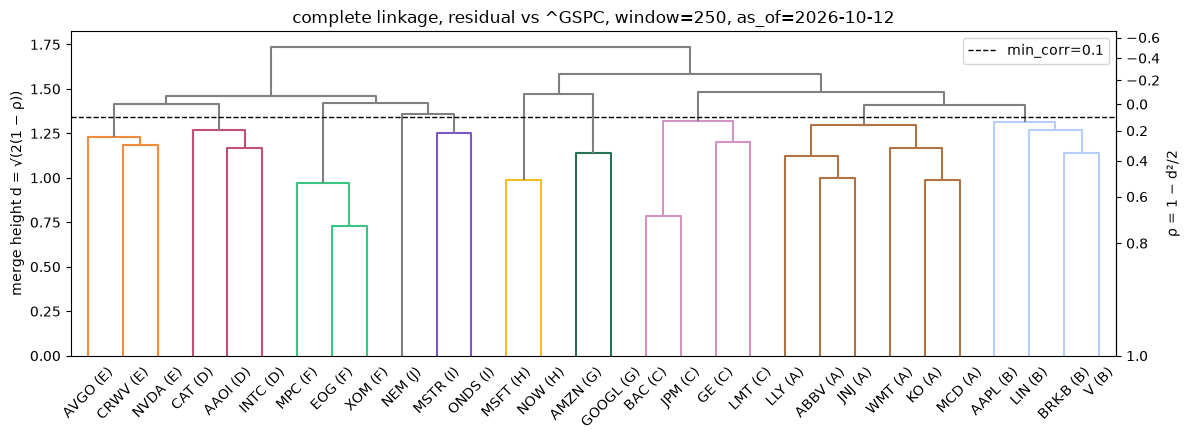

In [74]:
cp = cfg.cluster
Z, leaves = pf.cluster.linkage_tree(p, b, as_of, cp.window, cp.remove_market, cp.mkt, cp.method)
if len(leaves) < 2:
    print("Fewer than 2 stocks take part in clustering; cannot draw the dendrogram.")
else:
    h = np.sqrt(2 * (1 - cp.min_corr)) if cp.min_corr is not None else None
    fig, ax = plt.subplots(figsize=(12, 4.5))
    dendrogram(
        Z, labels=[f"{t} ({calculated_table.loc[t, 'cluster']})" for t in leaves],
        color_threshold=h if h is not None else 0,
        above_threshold_color="grey", ax=ax,
    )
    if h is not None:
        ax.axhline(h, ls="--", c="k", lw=1, label=f"min_corr={cp.min_corr:g}")
        ax.legend()
    ax.set_ylabel("merge height d = √(2(1 − ρ))")
    ax.secondary_yaxis("right", functions=(
        lambda d: 1 - d**2 / 2,
        lambda r: np.sqrt(np.clip(2 * (1 - r), 0, None)),
    )).set_ylabel("ρ = 1 − d²/2")
    basis = f"residual vs {cp.mkt}" if cp.remove_market else "raw returns"
    ax.set_title(f"{cp.method} linkage, {basis}, window={cp.window}, as_of={as_of.date()}")
    fig.tight_layout()
    plt.show()

## 6. Optional: override table values

By default the computed results are used. To explore, uncomment or add `.loc` assignments below, then run downward from this cell.
`calculated_table` keeps the original results; `table` is the table used by the subsequent selection and MVO. Predicted returns are decimals: 0.05 means an H-day return of 5%.
Overriding the total score does not back out the factors; overriding predicted returns does not recompute the total score automatically.

In [75]:
table = calculated_table.copy()
# table.loc["MSFT", "score"] = 2.0
# table.loc["MSFT", "cluster"] = "A"
# table.loc["MSFT", "predicted_return"] = 0.05
# table.loc["MSFT", "prediction_uncertainty"] = 0.01

display(table.sort_values("score", ascending=False, kind="stable").style.format(
    {"score": "{:.3f}", "predicted_return": "{:.2%}", "prediction_uncertainty": "{:.2%}"}, na_rep="—"))

,score,predicted_return,prediction_uncertainty,knn_neighbor_count,cluster
ticker,,,,,
MPC,1.349,1.25%,2.92%,15,F
AAOI,0.905,0.79%,11.25%,15,D
NVDA,0.851,2.23%,6.71%,15,E
LLY,0.791,5.91%,2.40%,15,A
AVGO,0.722,5.16%,3.76%,15,E
JPM,0.385,3.71%,1.48%,15,C
EOG,0.323,-7.18%,5.17%,15,F
INTC,0.308,1.83%,3.54%,15,D
V,0.179,3.97%,1.63%,15,B


## 7. Automatic selection

Filter by total score descending with a per-cluster cap; once `min_n` is reached, stop if the gap to the previous selected stock exceeds `max_gap`, at most `max_n` stocks.
The table below keeps the whole pool and marks the automatically selected stocks.

In [76]:
selection_method = cfg.selection.method
auto_selected = pf.selection.SELECTORS[selection_method](
    table["score"].dropna(), table["cluster"],
    **asdict(getattr(cfg.selection, selection_method)),
)
print(f"Automatic list ({len(auto_selected)} stocks): {', '.join(auto_selected)}")
display(table.assign(auto_selected=table.index.isin(auto_selected))
        .sort_values("score", ascending=False, kind="stable").style.format(
            {"score": "{:.3f}", "predicted_return": "{:.2%}"}, na_rep="—"))

Automatic list (6 stocks): MPC, AAOI, NVDA, LLY, AVGO, JPM


,score,predicted_return,prediction_uncertainty,knn_neighbor_count,cluster,auto_selected
ticker,,,,,,
MPC,1.349,1.25%,0.029230,15,F,True
AAOI,0.905,0.79%,0.112475,15,D,True
NVDA,0.851,2.23%,0.067097,15,E,True
LLY,0.791,5.91%,0.024044,15,A,True
AVGO,0.722,5.16%,0.037613,15,E,True
JPM,0.385,3.71%,0.014755,15,C,True
EOG,0.323,-7.18%,0.051715,15,F,False
INTC,0.308,1.83%,0.035374,15,D,False
V,0.179,3.97%,0.016274,15,B,False


## 8. Optional: set the list manually

`None` keeps the automatic list; a list of symbols replaces it entirely, e.g. `manual_selected = ["MSFT", "JNJ", "CAT", "WMT"]`.
A manual list is not bound by the automatic selection's count, cluster cap or score gap rules; any shortfall of stock weights below 1 becomes `CASH`, so a small number of stocks works too; MVO still checks prices, predicted returns, prediction uncertainty and weight constraints.
After editing, rerun downward from this cell; the evaluation will also use the weights for this list.

In [77]:
manual_selected = None

selected = auto_selected.copy() if manual_selected is None else list(manual_selected)
if not selected or len(selected) != len(set(selected)):
    raise ValueError("the final list must be non-empty with no duplicate symbols")
unknown = sorted(set(selected) - set(table.index))
if unknown:
    raise ValueError(f"these symbols are not in the candidate table: {unknown}")

print(f"{'Automatic' if manual_selected is None else 'Manual'} list ({len(selected)} stocks): {', '.join(selected)}")
display(table.loc[selected].style.format(
    {"score": "{:.3f}", "predicted_return": "{:.2%}", "prediction_uncertainty": "{:.2%}"}, na_rep="—"))

Automatic list (6 stocks): MPC, AAOI, NVDA, LLY, AVGO, JPM


,score,predicted_return,prediction_uncertainty,knn_neighbor_count,cluster
ticker,,,,,
MPC,1.349,1.25%,2.92%,15,F
AAOI,0.905,0.79%,11.25%,15,D
NVDA,0.851,2.23%,6.71%,15,E
LLY,0.791,5.91%,2.40%,15,A
AVGO,0.722,5.16%,3.76%,15,E
JPM,0.385,3.71%,1.48%,15,C


## 9. MVO weights

$$\max_w\ \mu^\top w-\kappa\sqrt{w^\top\Omega w},
\quad \mathbf1^\top w+w_{\mathrm{cash}}=1,\quad 0\le w_{\mathrm{cash}}\le1,\quad 0\le lower\le w_i\le upper,\quad
\sqrt{w^\top\Sigma w}\le\mathrm{max\_volatility}.$$

$\Sigma=H\times\mathrm{LedoitWolf}(r)$, $\Omega=\mathrm{diag}(u^2)$.
$\mu$ and $u$ are taken from the current table's `predicted_return` and `prediction_uncertainty`, by default from the same KNN run.
By default `config` forbids short selling, caps any single stock at 30%, and caps H-day portfolio volatility at 10% (the values in section E at the top take precedence); `CASH` has zero return and volatility, and any shortfall of stock weights below 1 becomes `CASH`; selected stocks may still get 0 weight.

In [78]:
weight_method = cfg.weights.method
w = pf.weights.WEIGHTERS[weight_method](
    p, table["predicted_return"], table["prediction_uncertainty"], selected, as_of,
    **asdict(getattr(cfg.weights, weight_method)), horizon=horizon,
)
display(table.reindex(w.index).assign(weight=w).style.format(
    {"score": "{:.3f}", "predicted_return": "{:.2%}", "prediction_uncertainty": "{:.2%}", "weight": "{:.2%}"}, na_rep="—"))
print(f"Total weight: {w.sum():.2%}")

,score,predicted_return,prediction_uncertainty,knn_neighbor_count,cluster,weight
MPC,1.349,1.25%,2.92%,15.000000,F,5.74%
AAOI,0.905,0.79%,11.25%,15.000000,D,0.00%
NVDA,0.851,2.23%,6.71%,15.000000,E,4.26%
LLY,0.791,5.91%,2.40%,15.000000,A,30.00%
AVGO,0.722,5.16%,3.76%,15.000000,E,30.00%
JPM,0.385,3.71%,1.48%,15.000000,C,30.00%
CASH,—,—,—,—,—,0.00%


Total weight: 100.00%


## 10. Single-period holding return

$V_t=w_{\mathrm{cash}}+\sum_i w_i P_{i,t}/P_{i,t_0}$, $r_t^p=V_t/V_{t-1}-1$, $R_H=\prod_{t=1}^{H}(1+r_t^p)-1$.

Buy with the actual weights from the previous step and hold for H days without rebalancing; only here are prices after the decision date used.

In [79]:
daily_returns = None
res = None
metrics = None
available_days = len(prices.index) - prices.index.get_loc(as_of) - 1
if available_days < horizon:
    print(f"only {available_days} trading days after as_of, fewer than {horizon}; keeping the portfolio, skipping holding returns and evaluation.")
else:
    daily_returns = pf.backtest.holding_returns(prices, w, as_of, horizon)
    period_index = pd.DatetimeIndex([as_of], name="as_of")
    base_daily, random_daily = pf.backtest.baseline_returns(prices, benchmarks, as_of, w, cfg)
    res = pf.backtest.BacktestResult(
        daily=daily_returns.to_frame(name=as_of).rename_axis(index="date", columns="as_of"),
        returns=daily_returns.rename_axis("date"),
        periods=pd.DataFrame({
            "end": [daily_returns.index[-1]],
            "period_return": [(1 + daily_returns).prod(skipna=False) - 1],
        }, index=period_index),
        weights=pd.DataFrame([w.reindex([*prices.columns, pf.weights.CASH])], index=period_index)
                  .rename_axis(columns="ticker"),
        # Baselines and random portfolios are built with the same number of selected stocks as w; for evaluation only, they do not affect the portfolio above.
        baseline_daily={k: r.to_frame(name=as_of).rename_axis(index="date", columns="as_of") for k, r in base_daily.items()},
        random_daily={as_of: random_daily},
        rf_daily=pf.backtest.rf_daily(benchmarks, prices.index, cfg.task.eval.risk_free, cfg.task.periods_per_year),
    )
    display(res.periods.style.format({"period_return": "{:.2%}"}, na_rep="—"))
    nav = pd.concat([
        pd.Series([1.0], index=pd.DatetimeIndex([as_of])),
        (1 + daily_returns).cumprod(skipna=False),
    ])
    display(pd.DataFrame({"daily_return": daily_returns, "nav": nav}).style.format(
        {"daily_return": "{:.2%}", "nav": "{:.4f}"}, na_rep="—"))
    nav.plot(title=f"Portfolio value · {as_of.date()}", figsize=(9, 3), grid=True)
    plt.show()

only 0 trading days after as_of, fewer than 39; keeping the portfolio, skipping holding returns and evaluation.


## 11. evaluate

Calls `metrics.period_table` and `metrics.evaluate` to evaluate only the single-period portfolio above, without reselecting stocks.
The per-period detail is ret / vol / sharpe / mdd for S and each baseline (gspc, ew_pool, ew_sel, mom, nvda), S's beta / alpha, and the ranks of S and ew_sel among random portfolios;
with a single period, the summary mean is just this period's value and se is NaN. If benchmarks has no risk-free rate ^IRX, the previous cell raises.

In [80]:
metrics = None
if res is None:
    print("Insufficient holding-period data; no complete single-period result to evaluate yet.")
else:
    display(pf.metrics.period_table(res, cfg).T.style.format("{:.4f}", na_rep="—"))
    metrics = pf.metrics.evaluate(res, cfg)
    display(pd.Series(metrics, name="Single-period evaluation").to_frame().style.format("{:.6f}", na_rep="—"))

Insufficient holding-period data; no complete single-period result to evaluate yet.


## 12. Comparison with the backtest pipeline

The step-by-step computation above is a copy of `backtest.decide` (and of how `run_backtest` assembles a single-period result), so intermediate results can be shown step by step.
Here the backtest functions are called directly with the same `as_of` and `cfg` to confirm both sides agree: if `decide` changes and this notebook is not updated accordingly, this raises.

- The score table (`calculated_table` before overrides) is always compared.
- When table values were overridden or a manual list was given, the subsequent weights and returns differ from the backtest by design; this only notes it and does not compare.
- When holding-period data is insufficient, single-period returns are not compared.

In [81]:
decide_table, decide_w = pf.backtest.decide(prices, fundamentals, benchmarks, as_of, cfg)
pd.testing.assert_frame_equal(calculated_table, decide_table)

if not table.equals(calculated_table) or manual_selected is not None:
    print("Score table matches backtest.decide; table values were overridden or a manual list was given, so weights and returns are not compared with the backtest.")
else:
    assert selected == auto_selected
    pd.testing.assert_series_equal(w, decide_w)
    if res is None:
        print("Score table and weights match backtest.decide; insufficient holding-period data, single-period returns not compared.")
    else:
        run_check = pf.config.RunSpec(start=str(as_of.date()), end=str(res.periods["end"].iloc[0].date()),
                                      step=horizon, label="demoex", note="demoex")
        bt = pf.backtest.run_backtest(prices, fundamentals, benchmarks, cfg, run_check)
        pd.testing.assert_frame_equal(res.periods, bt.periods)
        pd.testing.assert_frame_equal(res.weights, bt.weights)
        pd.testing.assert_frame_equal(res.daily, bt.daily)
        pd.testing.assert_series_equal(res.returns, bt.returns)
        assert res.baseline_daily.keys() == bt.baseline_daily.keys()
        for k in res.baseline_daily:
            pd.testing.assert_frame_equal(res.baseline_daily[k], bt.baseline_daily[k])
        pd.testing.assert_frame_equal(res.random_daily[as_of], bt.random_daily[as_of])
        pd.testing.assert_series_equal(res.rf_daily, bt.rf_daily)
        print("Score table, weights, single-period returns, baselines and random portfolios match backtest.decide / run_backtest.")

Score table and weights match backtest.decide; insufficient holding-period data, single-period returns not compared.


/Users/tingshuoliang/Downloads/Part1_codes/pf/factors.py:257: UserWarning: as_of=2026-10-12: after time de-duplication, neighbors are fewer than min_neighbors=8; still predicting with the existing window: ONDS=4
  return predict_return_details(
